# 00 · Inspect the downloaded data

A quick, basic look at everything `scripts/00_download_data.sh` put in `data/`:

1. LibriSpeech dev-clean + test-clean (audio + transcripts)
2. TextGrid word alignments
3. MASE splits for Fluent Speech Commands and Snips SmartLights (transcripts + labels; audio is gated)
4. WordNet
5. CMU Pronouncing Dictionary (comes from the `cmudict` pip package)

Needs only numpy / pandas / matplotlib. Sections 4–5 show extra demos if `nltk` / `cmudict` are installed.

In [1]:
import re, sys, struct
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Audio, display

sys.path.insert(0, str(Path.cwd().parent))   # notebook lives in notebooks/
import config as C

pd.set_option("display.width", 120)

def dir_size(p):
    return sum(f.stat().st_size for f in Path(p).rglob("*") if f.is_file())

pd.DataFrame(
    [(p.name, f"{dir_size(p) / 1e6:,.0f} MB") for p in sorted(C.DATA_DIR.iterdir()) if p.is_dir()],
    columns=["folder", "size"],
)

,folder,size
0,LibriSpeech,728 MB
1,_downloads,"1,318 MB"
2,librispeech_alignments,39 MB
3,mase,32 MB
4,nltk_data,36 MB


## 1. LibriSpeech audio + transcripts

In [2]:
def flac_info(path):
    """Sample rate, channels, bits, duration from the FLAC STREAMINFO header (no decoding)."""
    with open(path, "rb") as f:
        head = f.read(42)
    assert head[:4] == b"fLaC"
    x = int.from_bytes(head[18:26], "big")
    sr = x >> 44
    return sr, ((x >> 41) & 7) + 1, ((x >> 36) & 31) + 1, (x & ((1 << 36) - 1)) / sr

rows = []
for split in C.LIBRISPEECH_SPLITS:
    for trans in (C.LIBRISPEECH_DIR / split).rglob("*.trans.txt"):
        for line in trans.read_text().splitlines():
            utt, text = line.split(" ", 1)
            spk, chap, _ = utt.split("-")
            flac = trans.parent / f"{utt}.flac"
            sr, ch, bits, dur = flac_info(flac)
            rows.append(dict(split=split, utt=utt, speaker=int(spk), chapter=int(chap),
                             text=text, n_words=len(text.split()), sr=sr, channels=ch,
                             bits=bits, dur=dur, flac=flac))
utts = pd.DataFrame(rows)
utts.head()

,split,utt,speaker,chapter,text,n_words,sr,channels,bits,dur,flac
0,dev-clean,174-50561-0000,174,50561,FORGOTTEN TOO THE NAME OF GILLIAN THE LOVELY C...,9,16000,1,16,4.020,/home/vibhav/Documents/SAL-project/data/LibriS...
1,dev-clean,174-50561-0001,174,50561,WORSE AND WORSE HE IS EVEN PRESUMED TO BE THE ...,50,16000,1,16,15.860,/home/vibhav/Documents/SAL-project/data/LibriS...
2,dev-clean,174-50561-0002,174,50561,BUT THIS IS A FALLACY,5,16000,1,16,2.145,/home/vibhav/Documents/SAL-project/data/LibriS...
3,dev-clean,174-50561-0003,174,50561,THE WANDERING SINGER APPROACHES THEM WITH HIS ...,8,16000,1,16,3.340,/home/vibhav/Documents/SAL-project/data/LibriS...
4,dev-clean,174-50561-0004,174,50561,THE EMPEROR'S DAUGHTER,3,16000,1,16,2.060,/home/vibhav/Documents/SAL-project/data/LibriS...


In [3]:
print("sample rates:", utts.sr.unique(), "| channels:", utts.channels.unique(), "| bits:", utts.bits.unique())
utts.groupby("split").agg(
    utterances=("utt", "size"), speakers=("speaker", "nunique"), chapters=("chapter", "nunique"),
    hours=("dur", lambda d: round(d.sum() / 3600, 2)), mean_dur_s=("dur", "mean"),
    words=("n_words", "sum"),
).round(2)

sample rates: [16000] | channels: [1] | bits: [16]


,utterances,speakers,chapters,hours,mean_dur_s,words
split,,,,,,
dev-clean,2703,40,97,5.39,7.18,54402
test-clean,2620,40,87,5.40,7.42,52576


In [4]:
# Speaker metadata (gender) from SPEAKERS.TXT
spk_rows = [l.split("|") for l in (C.LIBRISPEECH_DIR / "SPEAKERS.TXT").read_text().splitlines()
            if l.strip() and not l.startswith(";")]
speakers = pd.DataFrame([[c.strip() for c in r[:5]] for r in spk_rows],
                        columns=["speaker", "sex", "subset", "minutes", "name"])
speakers = speakers[speakers.subset.isin(C.LIBRISPEECH_SPLITS)].astype({"speaker": int})
speakers.groupby(["subset", "sex"]).size().unstack()

sex,F,M
subset,,
dev-clean,20,20
test-clean,20,20


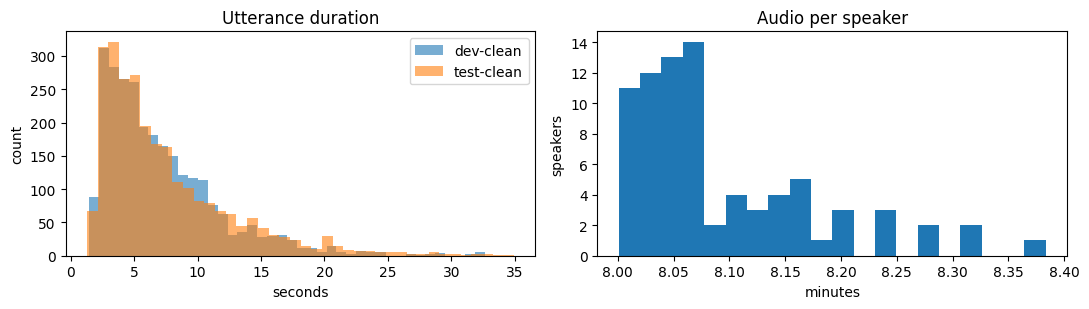

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
for split, g in utts.groupby("split"):
    ax[0].hist(g.dur, bins=40, alpha=.6, label=split)
ax[0].set(title="Utterance duration", xlabel="seconds", ylabel="count"); ax[0].legend()
per_spk = utts.groupby("speaker").dur.sum() / 60
ax[1].hist(per_spk, bins=20)
ax[1].set(title="Audio per speaker", xlabel="minutes", ylabel="speakers")
plt.tight_layout()

In [6]:
# Listen to one short utterance (plays in the browser, no audio library needed)
ex = utts[utts.dur.between(3, 5)].iloc[0]
print(ex.utt, f"({ex.dur:.1f}s):", ex.text)
display(Audio(filename=str(ex.flac)))

174-50561-0000 (4.0s): FORGOTTEN TOO THE NAME OF GILLIAN THE LOVELY CAPTIVE


## 2. TextGrid word alignments

Each utterance has a TextGrid with a `words` tier (and a `phones` tier). These start/end times are
what we use to cut single words out of the audio.

In [7]:
INTERVAL = re.compile(r'xmin = ([\d.]+)\s+xmax = ([\d.]+)\s+text = "(.*?)"')

def read_words_tier(path):
    """(start, end, word) for every non-empty interval of the 'words' tier."""
    txt = Path(path).read_text()
    for item in txt.split("item [")[2:]:          # [0] header, [1] "item []:"
        if 'name = "words"' in item:
            return [(float(a), float(b), w) for a, b, w in INTERVAL.findall(item) if w.strip()]
    return []

tg_paths = {p.stem: p for split in C.LIBRISPEECH_SPLITS
            for p in (C.ALIGNMENTS_DIR / split).rglob("*.TextGrid")}
print("utterances with audio:", len(utts), "| TextGrids:", len(tg_paths),
      "| audio without TextGrid:", len(set(utts.utt) - set(tg_paths)))

rows = []
for u in utts.itertuples():
    for start, end, w in read_words_tier(tg_paths[u.utt]):
        rows.append(dict(split=u.split, utt=u.utt, speaker=u.speaker, word=w, start=start, end=end))
words = pd.DataFrame(rows)
words["dur"] = words.end - words.start
words.head()

utterances with audio: 5323 | TextGrids: 5323 | audio without TextGrid: 0


,split,utt,speaker,word,start,end,dur
0,dev-clean,174-50561-0000,174,forgotten,0.51,1.05,0.54
1,dev-clean,174-50561-0000,174,too,1.05,1.45,0.40
2,dev-clean,174-50561-0000,174,the,1.48,1.57,0.09
3,dev-clean,174-50561-0000,174,name,1.57,1.77,0.20
4,dev-clean,174-50561-0000,174,of,1.77,1.89,0.12


In [8]:
# Sanity check: aligned words should equal the transcript words
aligned = words.groupby("utt").word.apply(lambda w: " ".join(w).upper())
match = (utts.set_index("utt").text == aligned.reindex(utts.utt).values)
print(f"utterances where alignment == transcript: {match.mean():.1%}")

# Mismatches come from the aligner, not missing data: out-of-dictionary words become "<unk>",
# and some apostrophe words are split ("'s", "'d"). These tokens get filtered out in step 01.
mism = Counter()
for utt in utts.utt[~match.values]:
    mism.update(set(aligned[utt].split()) - set(utts.set_index("utt").text[utt].split()))
print("tokens only in alignments:", mism.most_common(6))
print(f"<unk> word tokens: {(words.word == '<unk>').sum():,} of {len(words):,}")

utterances where alignment == transcript: 93.2%
tokens only in alignments: [('<UNK>', 344), ('S', 41), ('D', 6), ('GWYNPLAINE', 3), ('ABALONE', 2), ('WARRENTON', 2)]
<unk> word tokens: 390 of 107,027


In [9]:
print(f"word tokens: {len(words):,} | vocabulary: {words.word.nunique():,} | speakers: {words.speaker.nunique()}")
counts = words.word.value_counts()
print(f"words seen once: {(counts == 1).sum():,} ({(counts == 1).mean():.0%} of vocabulary)")
print(f"words seen >= 2 times (can form same-word pairs): {(counts >= 2).sum():,}")
counts.head(15).to_frame("count").T

word tokens: 107,027 | vocabulary: 12,012 | speakers: 80
words seen once: 5,873 (49% of vocabulary)
words seen >= 2 times (can form same-word pairs): 6,139


word,the,and,of,to,a,in,i,was,that,he,it,his,with,is,for
count,6909,3702,3536,2718,2364,1845,1339,1263,1252,1205,1185,1063,894,837,821


,count,mean,std,min,25%,50%,75%,max
dur,107027.0,0.303,0.185,0.03,0.15,0.26,0.42,1.61


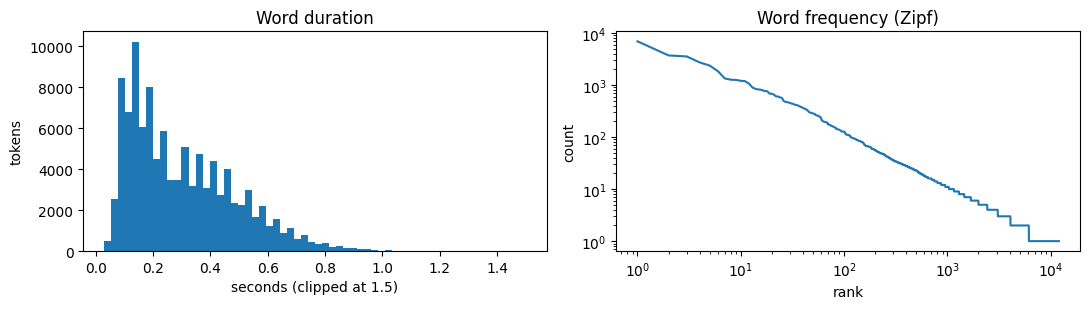

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].hist(words.dur.clip(upper=1.5), bins=60)
ax[0].set(title="Word duration", xlabel="seconds (clipped at 1.5)", ylabel="tokens")
ax[1].loglog(np.arange(1, len(counts) + 1), counts.values)
ax[1].set(title="Word frequency (Zipf)", xlabel="rank", ylabel="count")
plt.tight_layout()
words.dur.describe().round(3).to_frame().T

## 3. MASE splits: Fluent Speech Commands + Snips SmartLights

Only the split CSVs (transcripts + intent labels) are here. The audio needs an access request, so
we only check whether it is present.

In [11]:
SLU = C.MASE_DIR / "slu_splits"
rows = []
for ds in ["fluent_speech_commands", "snips_close_field"]:
    for csv in sorted((SLU / ds).rglob("*.csv")):
        df = pd.read_csv(csv, index_col=0 if ds == "fluent_speech_commands" else None)
        rows.append(dict(dataset=ds, split_style=csv.relative_to(SLU / ds).parts[0],
                         file=csv.stem, rows=len(df), speakers=df.speakerId.nunique(),
                         unique_transcripts=df.transcription.nunique()))
pd.DataFrame(rows).set_index(["dataset", "split_style", "file"])

rows  speakers  unique_transcripts
dataset                split_style      file                                                    
fluent_speech_commands challenge_splits speaker_test_data     3349        17                 206
                                        train_data           19262        80                 206
                                        utterance_test_data   4204        77                  42
                                        valid_data            2597        78                 206
                       original_splits  test_data             3793        10                 248
                                        train_data           23132        77                 248
                                        valid_data            3118        10                 248
                       random_splits    test_data             3791        95                 248
                                        train_data           23134        97                 248
                                        valid_data            3118        93                 248
                       unseen_splits    speaker_test_data     3366        13                 208
                                        train_data           19463        84                 208
                                        utterance_test_data   3971        82                  40
                                        valid_data            2624        83                 208
snips_close_field      challenge_splits speaker_test_data      127        13                 127
                                        train_data            1251        39                1251
                                        utterance_test_data    126        25                 126
                                        valid_data             156        28                 156
                       original_splits  test_data              167        36                 167
                                        train_data            1328        52                1328
                                        valid_data             165        39                 165
                       random_splits    test_data              167        36                 167
                                        train_data            1328        52                1328
                                        valid_data             165        39                 165
                       unseen_splits    test_data              168        14                 168
                                        train_data            1327        36                1327
                                        valid_data             165         3                 165

In [12]:
fsc = pd.read_csv(SLU / "fluent_speech_commands/original_splits/train_data.csv", index_col=0)
fsc["intent"] = fsc.action + " | " + fsc.object + " | " + fsc.location
print(f"FSC train: {len(fsc):,} utterances, {fsc.intent.nunique()} intents, "
      f"{fsc.transcription.nunique()} distinct transcripts")
fsc.head()

FSC train: 23,132 utterances, 31 intents, 248 distinct transcripts


,path,speakerId,transcription,action,object,location,intent
0,wavs/speakers/2BqVo8kVB2Skwgyb/0a3129c0-4474-1...,2BqVo8kVB2Skwgyb,Change language,change language,none,none,change language | none | none
1,wavs/speakers/2BqVo8kVB2Skwgyb/0ee42a80-4474-1...,2BqVo8kVB2Skwgyb,Resume,activate,music,none,activate | music | none
2,wavs/speakers/2BqVo8kVB2Skwgyb/144d5be0-4474-1...,2BqVo8kVB2Skwgyb,Turn the lights on,activate,lights,none,activate | lights | none
3,wavs/speakers/2BqVo8kVB2Skwgyb/1811b6e0-4474-1...,2BqVo8kVB2Skwgyb,Switch on the lights,activate,lights,none,activate | lights | none
4,wavs/speakers/2BqVo8kVB2Skwgyb/1d9f3920-4474-1...,2BqVo8kVB2Skwgyb,Switch off the lights,deactivate,lights,none,deactivate | lights | none


In [13]:
snips = pd.read_csv(SLU / "snips_close_field/original_splits/data/train_data.csv")
print(f"Snips train: {len(snips):,} utterances, {snips.intent.nunique()} intents, "
      f"{snips.transcription.nunique()} distinct transcripts")
snips.head()

Snips train: 1,328 utterances, 6 intents, 1328 distinct transcripts


,path,speakerId,transcription,intent,intentLbl
0,../smart-lights-en-close-field/speech_corpus/a...,143921a6-6caa-417f-bd7e-2732023270c1,Set the brightness in the kids room to level t...,SetLightBrightness,2
1,../smart-lights-en-close-field/speech_corpus/a...,61febf20-bc56-49b9-8e3a-e2ec25b362e6,Turn the lights up in the toilets.,IncreaseBrightness,1
2,../smart-lights-en-close-field/speech_corpus/a...,4e1a0afa-74e0-4d34-a6cd-ae2d96067f0f,Put the lights on,SwitchLightOn,5
3,../smart-lights-en-close-field/speech_corpus/a...,d74e7c3a-9e2f-40ea-a6da-cf1399adc25c,I would like the brightness of the lights to b...,SetLightBrightness,2
4,../smart-lights-en-close-field/speech_corpus/a...,61febf20-bc56-49b9-8e3a-e2ec25b362e6,I'd like the bedroom lights to be at ten percent,SetLightBrightness,2


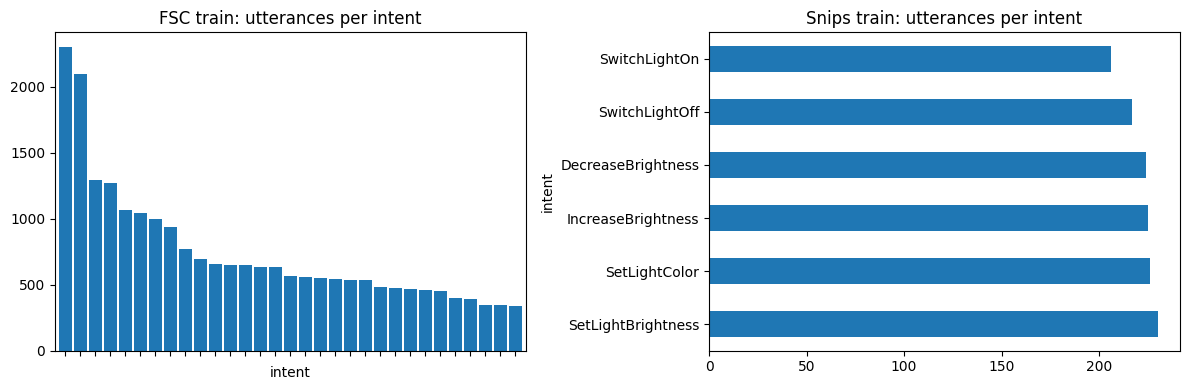

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
fsc.intent.value_counts().plot.bar(ax=ax[0], width=.9)
ax[0].set(title="FSC train: utterances per intent", xticklabels=[])
snips.intent.value_counts().plot.barh(ax=ax[1])
ax[1].set(title="Snips train: utterances per intent")
plt.tight_layout()

In [15]:
# Few distinct transcripts per intent -> a word-counting (BoW) model can already do very well.
print("FSC distinct transcripts per intent:  ", fsc.groupby("intent").transcription.nunique().describe()[["mean", "min", "max"]].round(1).to_dict())
print("Snips distinct transcripts per intent:", snips.groupby("intent").transcription.nunique().describe()[["mean", "min", "max"]].round(1).to_dict())
for name, d in [("FSC", C.FSC_DIR), ("Snips", C.SNIPS_DIR)]:
    n = sum(1 for _ in d.rglob("*.wav")) if d.exists() else 0
    print(f"{name} audio in {d.relative_to(C.ROOT)}: {n} wav files" + ("  <- request access" if n == 0 else ""))

FSC distinct transcripts per intent:   {'mean': 8.0, 'min': 4.0, 'max': 24.0}
Snips distinct transcripts per intent: {'mean': 221.3, 'min': 206.0, 'max': 230.0}
FSC audio in data/fsc: 0 wav files  <- request access
Snips audio in data/snips: 0 wav files  <- request access


## 4. WordNet (for same-meaning pairs)

In [16]:
wn_dir = C.NLTK_DATA_DIR / "corpora" / "wordnet"
for pos in ["noun", "verb", "adj", "adv"]:
    lemmas = [l.split()[0] for l in (wn_dir / f"index.{pos}").read_text().splitlines() if not l.startswith(" ")]
    print(f"{pos:5s}: {len(lemmas):,} lemmas")

try:
    from nltk.corpus import wordnet as wn          # uses NLTK_DATA set in config.py
    for w in ["dog", "light", "quick"]:
        syn = sorted({l.name() for s in wn.synsets(w) for l in s.lemmas()} - {w})
        print(f"{w}: {syn[:10]}")
    in_wn = pd.Series(counts.index).map(lambda w: len(wn.synsets(w)) > 0)
    print(f"LibriSpeech vocabulary found in WordNet: {in_wn.mean():.0%}")
except ImportError:
    print("(nltk not installed: skip synonym demo)")

noun : 117,798 lemmas
verb : 11,529 lemmas
adj  : 21,479 lemmas
adv  : 4,481 lemmas


dog: ['Canis_familiaris', 'andiron', 'blackguard', 'bounder', 'cad', 'chase', 'chase_after', 'click', 'detent', 'dog-iron']
light: ['Christ_Within', 'Inner_Light', 'Light', 'Light_Within', 'abstemious', 'alight', 'brightness', 'brightness_level', 'calorie-free', 'clean']
quick: ['agile', 'fast', 'flying', 'immediate', 'nimble', 'prompt', 'promptly', 'quickly', 'ready', 'speedy']


LibriSpeech vocabulary found in WordNet: 92%


## 5. CMU Pronouncing Dictionary (for sound-alike pairs)

In [17]:
try:
    import cmudict
    cmu = cmudict.dict()
    print(f"{len(cmu):,} words in CMUdict")
    for w in ["dog", "dig", "puppy", "read"]:
        print(f"{w}: {cmu.get(w)}")
    print(f"LibriSpeech vocabulary found in CMUdict: {pd.Series(counts.index).isin(cmu).mean():.0%}")
except ImportError:
    print("(cmudict not installed: `pip install cmudict==1.0.15`, ~1 MB, bundles the dictionary)")

126,052 words in CMUdict
dog: [['D', 'AO1', 'G']]
dig: [['D', 'IH1', 'G']]
puppy: [['P', 'AH1', 'P', 'IY0']]
read: [['R', 'EH1', 'D'], ['R', 'IY1', 'D']]
LibriSpeech vocabulary found in CMUdict: 91%


## Summary

- LibriSpeech dev-clean + test-clean: utterance / speaker / hour counts above; every utterance has a TextGrid.
- Word alignments give the word table for step 01 (`scripts/01_build_word_table.py`).
- FSC / Snips: splits and labels are here, audio is still missing (access requests pending).
- WordNet is on disk; CMUdict arrives with the `cmudict` package.